In [1]:
import healpy as hp
%matplotlib inline
from new_footprints import (FootprintMod1, FootprintMod2, FootprintMod3, FootprintMod4,
                            FootprintMod5, FootprintMod6, FootprintMod7, FootprintMod8,
FootprintMod9,)
import numpy as np
from rubin_scheduler.scheduler.utils import Phase3AreaMap
import pandas as pd

In [2]:
area_lists = []
nside = 64

# Current baseline footprint

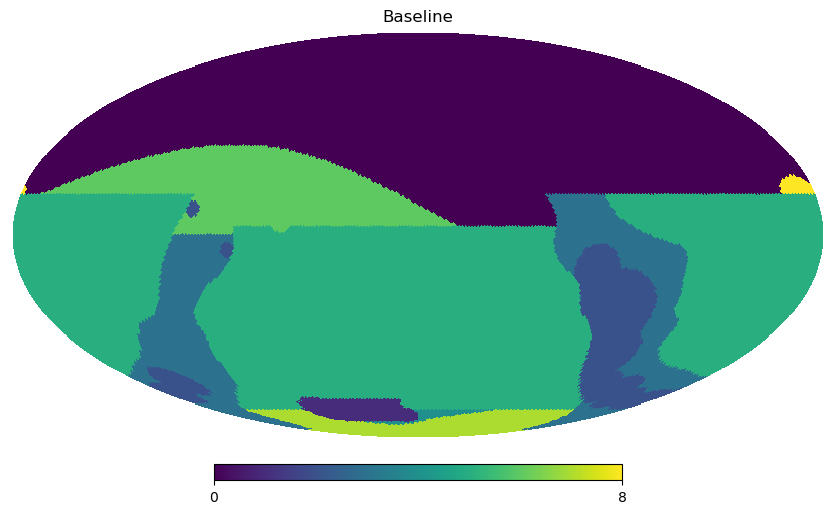

In [3]:

sag = Phase3AreaMap(nside=nside)
sky_maps, labels = sag.return_maps()

label_int = np.zeros(hp.nside2npix(nside))
for i,label in enumerate(np.unique(labels)):
    indx = np.where(labels == label)[0]
    label_int[indx] = i
hp.mollview(label_int, title="Baseline")

areas = {}
for lab in np.unique(labels):
    if lab != "":
        areas[lab] = np.size(np.where(labels == lab)[0])*hp.nside2pixarea(nside, degrees=True)

area_lists.append(pd.DataFrame(areas, index=["Baseline"]))

# From Knut's notebook fits output

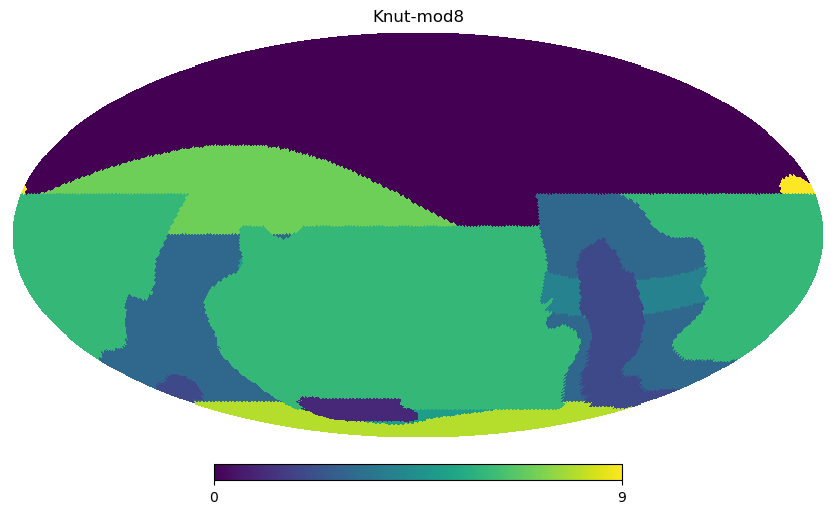

In [4]:

sag = FootprintMod8(nside=nside)
sky_maps, labels = sag.return_maps()

label_int = np.zeros(hp.nside2npix(nside))
for i,label in enumerate(np.unique(labels)):
    indx = np.where(labels == label)[0]
    label_int[indx] = i
hp.mollview(label_int, title="Knut-mod8")

areas = {}
for lab in np.unique(labels):
    if lab != "":
        areas[lab] = np.size(np.where(labels == lab)[0])*hp.nside2pixarea(nside, degrees=True)

area_lists.append(pd.DataFrame(areas, index=["Knut-mod8"]))

# Refactor to mostly match Knut

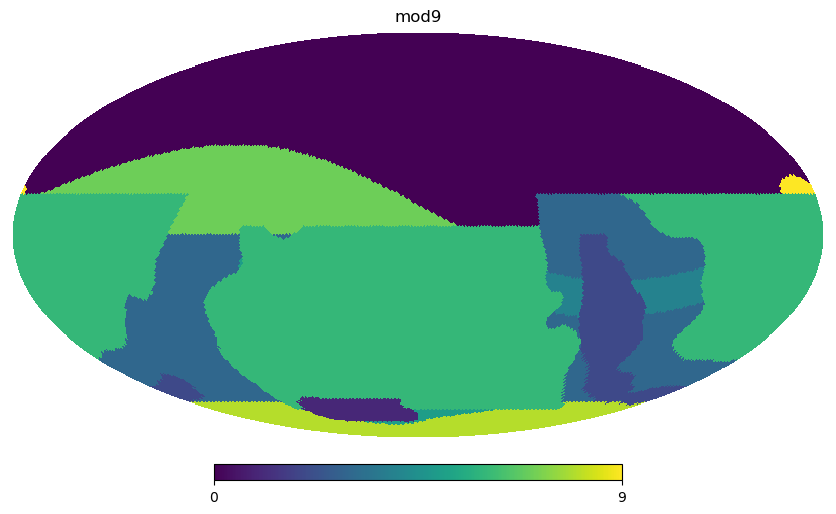

In [5]:
sag = FootprintMod9(nside=nside)
sky_maps, labels = sag.return_maps()

label_int = np.zeros(hp.nside2npix(nside))
for i,label in enumerate(np.unique(labels)):
    indx = np.where(labels == label)[0]
    label_int[indx] = i
hp.mollview(label_int, title="mod9")

areas = {}
for lab in np.unique(labels):
    if lab != "":
        areas[lab] = np.size(np.where(labels == lab)[0])*hp.nside2pixarea(nside, degrees=True)

area_lists.append(pd.DataFrame(areas, index=["mod9"]))

In [6]:
# Areas in sq degrees
ack = pd.concat(area_lists)
ack

,LMC_SMC,bulgy,dusty_plane,euclid_overlap,lowdust,nes,scp,virgo,ecliptic_bridge
Baseline,352.503331,1765.873830,3370.603279,94.000888,17565.576701,3134.761765,810.757661,83.090071,NaN
Knut-mod8,352.503331,1514.925030,4754.598500,98.197356,15490.003516,3233.798415,1140.600064,83.090071,584.987671
mod9,352.503331,1483.871165,4730.258984,98.197356,15566.379238,3233.798415,1174.171810,83.090071,530.433584


# Check that the WFD low dust areas match

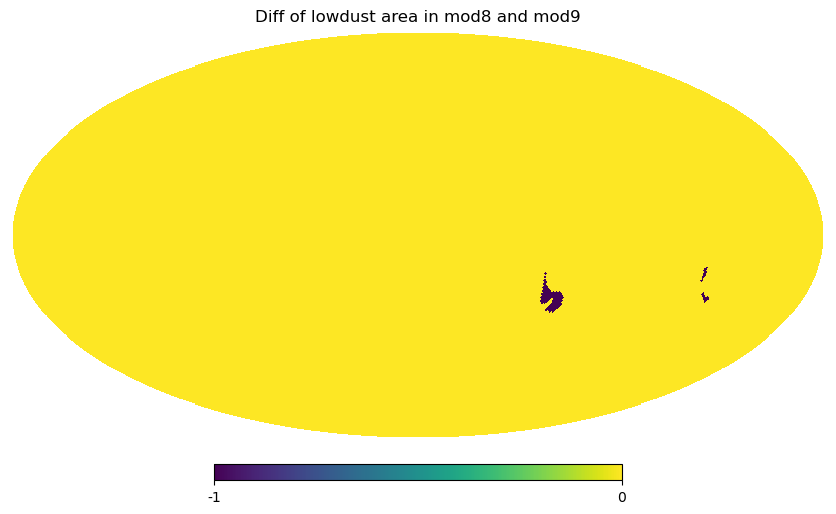

In [7]:
# compare lowdust regions
sag = FootprintMod8(nside=nside)
sky_maps_m8, labels_m8 = sag.return_maps()
wfd_8 = np.zeros(hp.nside2npix(nside))
wfd_8[np.where(labels_m8 == "lowdust")] = 1


sag = FootprintMod9(nside=nside)
sky_maps_m9, labels_m9 = sag.return_maps()
wfd_9 = np.zeros(hp.nside2npix(nside))
wfd_9[np.where(labels_m9 == "lowdust")] = 1

hp.mollview(wfd_8-wfd_9, title="Diff of lowdust area in mod8 and mod9")

# See what happens if we cut more on stellar density

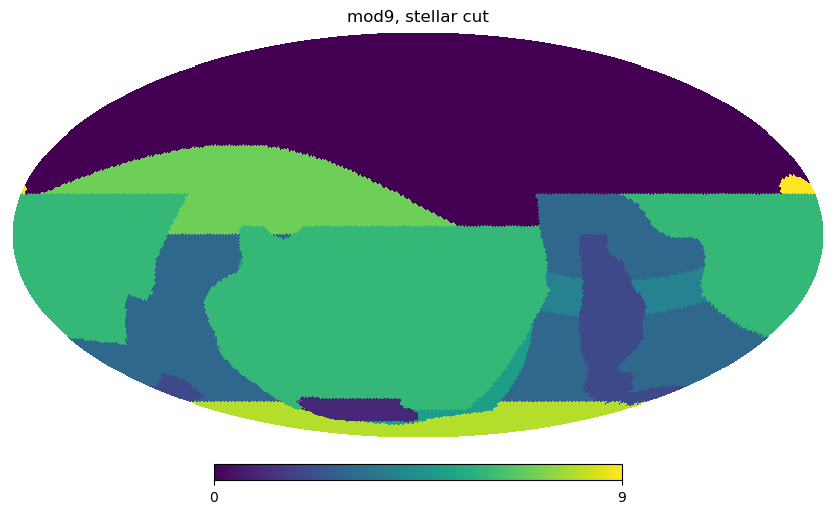

In [8]:
sag = FootprintMod9(nside=nside, stellar_density_max=1000)
sky_maps, labels = sag.return_maps()

label_int = np.zeros(hp.nside2npix(nside))
for i,label in enumerate(np.unique(labels)):
    indx = np.where(labels == label)[0]
    label_int[indx] = i
hp.mollview(label_int, title="mod9, stellar cut")

areas = {}
for lab in np.unique(labels):
    if lab != "":
        areas[lab] = np.size(np.where(labels == lab)[0])*hp.nside2pixarea(nside, degrees=True)

area_lists.append(pd.DataFrame(areas, index=["mod9-stellar"]))

In [9]:
ack = pd.concat(area_lists)
ack

,LMC_SMC,bulgy,dusty_plane,euclid_overlap,lowdust,nes,scp,virgo,ecliptic_bridge
Baseline,352.503331,1765.873830,3370.603279,94.000888,17565.576701,3134.761765,810.757661,83.090071,NaN
Knut-mod8,352.503331,1514.925030,4754.598500,98.197356,15490.003516,3233.798415,1140.600064,83.090071,584.987671
mod9,352.503331,1483.871165,4730.258984,98.197356,15566.379238,3233.798415,1174.171810,83.090071,530.433584
mod9-stellar,352.503331,1483.871165,5948.074064,297.949244,14014.525288,3233.798415,1250.547531,83.090071,588.344845
